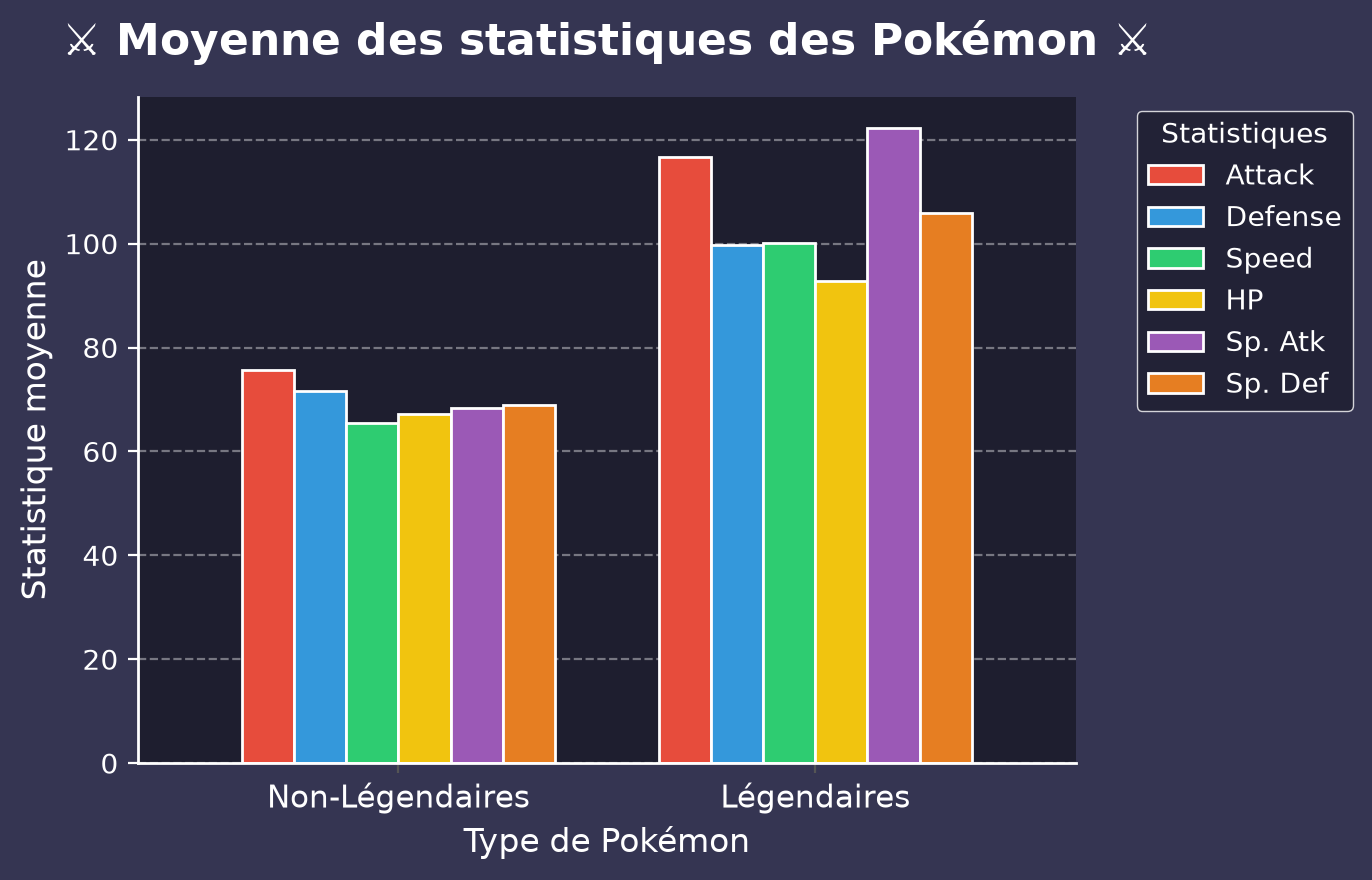

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use("ggplot")
plt.rcParams["axes.facecolor"] = "#A39F9F"
plt.rcParams["figure.facecolor"] = "#A39F9F"
plt.rcParams["figure.dpi"] = 200

url = "https://gist.githubusercontent.com/armgilles/194bcff35001e7eb53a2a8b441e8b2c6/raw/pokemon.csv"
df = pd.read_csv(url)

# ==========================
# Stats legendaire
# ==========================

stats = df.groupby("Legendary")[["Attack", "Defense", "Speed", "HP", "Sp. Atk", "Sp. Def"]].mean()

# Couleurs des statistiques
colors = [
    "#E74C3C",  # Attack
    "#3498DB",  # Defense
    "#2ECC71",  # Speed
    "#F1C40F",  # HP
    "#9B59B6",  # Sp. Atk
    "#E67E22"   # Sp. Def
]

ax = stats.plot(
    kind="bar",
    figsize=(7,4.5),
    width=0.75,
    color=colors,
    edgecolor="white",
    linewidth=1
)

# Fond sombre
ax.set_facecolor("#1E1E2F")
ax.figure.set_facecolor("#353552")

# Titre et axes
ax.set_title(
    "⚔️ Moyenne des statistiques des Pokémon ⚔️",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Type de Pokémon", fontsize=12, color="white")
ax.set_ylabel("Statistique moyenne", fontsize=12, color="white")

# Étiquettes
ax.set_xticks([0, 1])
ax.set_xticklabels(["Non-Légendaires", "Légendaires"], color="white", fontsize=11)
plt.xticks(rotation = 0)

ax.tick_params(axis="y", colors="white")

# Grille
ax.grid(axis="y", linestyle="--", alpha=0.4, color="white")
ax.grid(axis="x", visible=False)

# Légende
legend = ax.legend(
    title="Statistiques",
    facecolor="#1E1E2F",
    edgecolor="white",
    bbox_to_anchor=(1.05,1)
)
plt.setp(legend.get_title(), color="white")
for text in legend.get_texts():
    text.set_color("white")

# Supprime les bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()




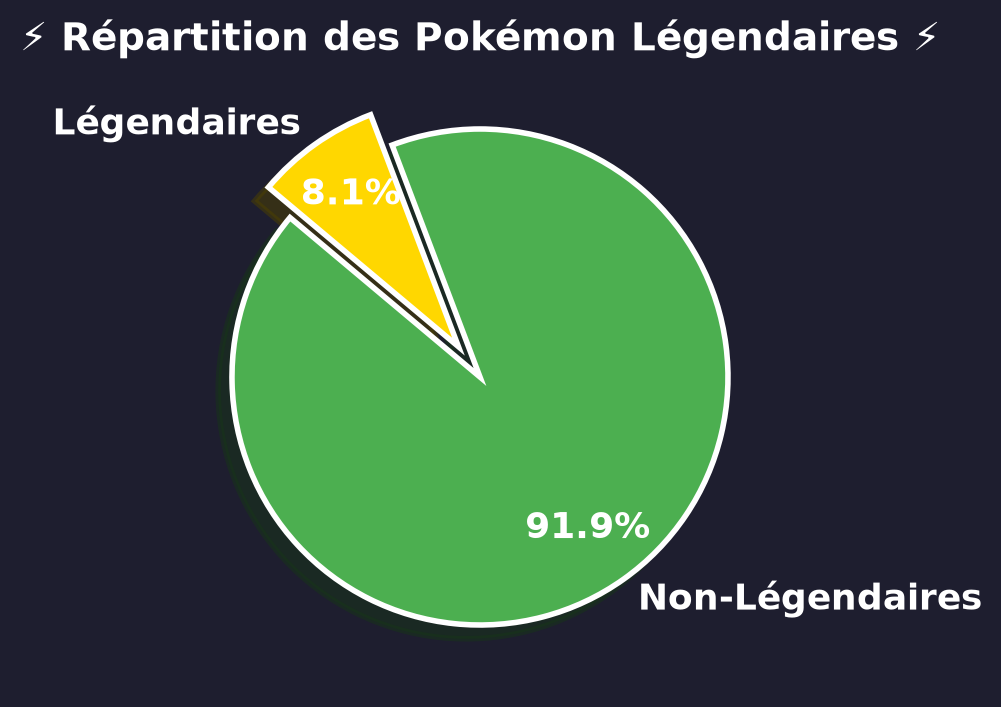

In [46]:
colors = ["#4CAF50", "#FFD700"]  # Vert / Or

plt.figure(figsize=(4,9), facecolor="#1E1E2F")
legendary = df["Legendary"].value_counts()

plt.pie(
    legendary,
    labels=["Non-Légendaires", "Légendaires"],
    colors=colors,
    explode=(0,0.15),
    startangle=140,
    shadow=True,
    autopct="%1.1f%%",
    pctdistance=0.75,
    textprops={
        "color":"white",
        "fontsize":13,
        "fontweight":"bold"
    },
    wedgeprops=dict(edgecolor="white", linewidth=2)
)

plt.title(
    "⚡ Répartition des Pokémon Légendaires ⚡",
    color="white",
    fontsize=14,
    fontweight="bold"
)

plt.gca().set_facecolor("#1E1E2F")
plt.show()

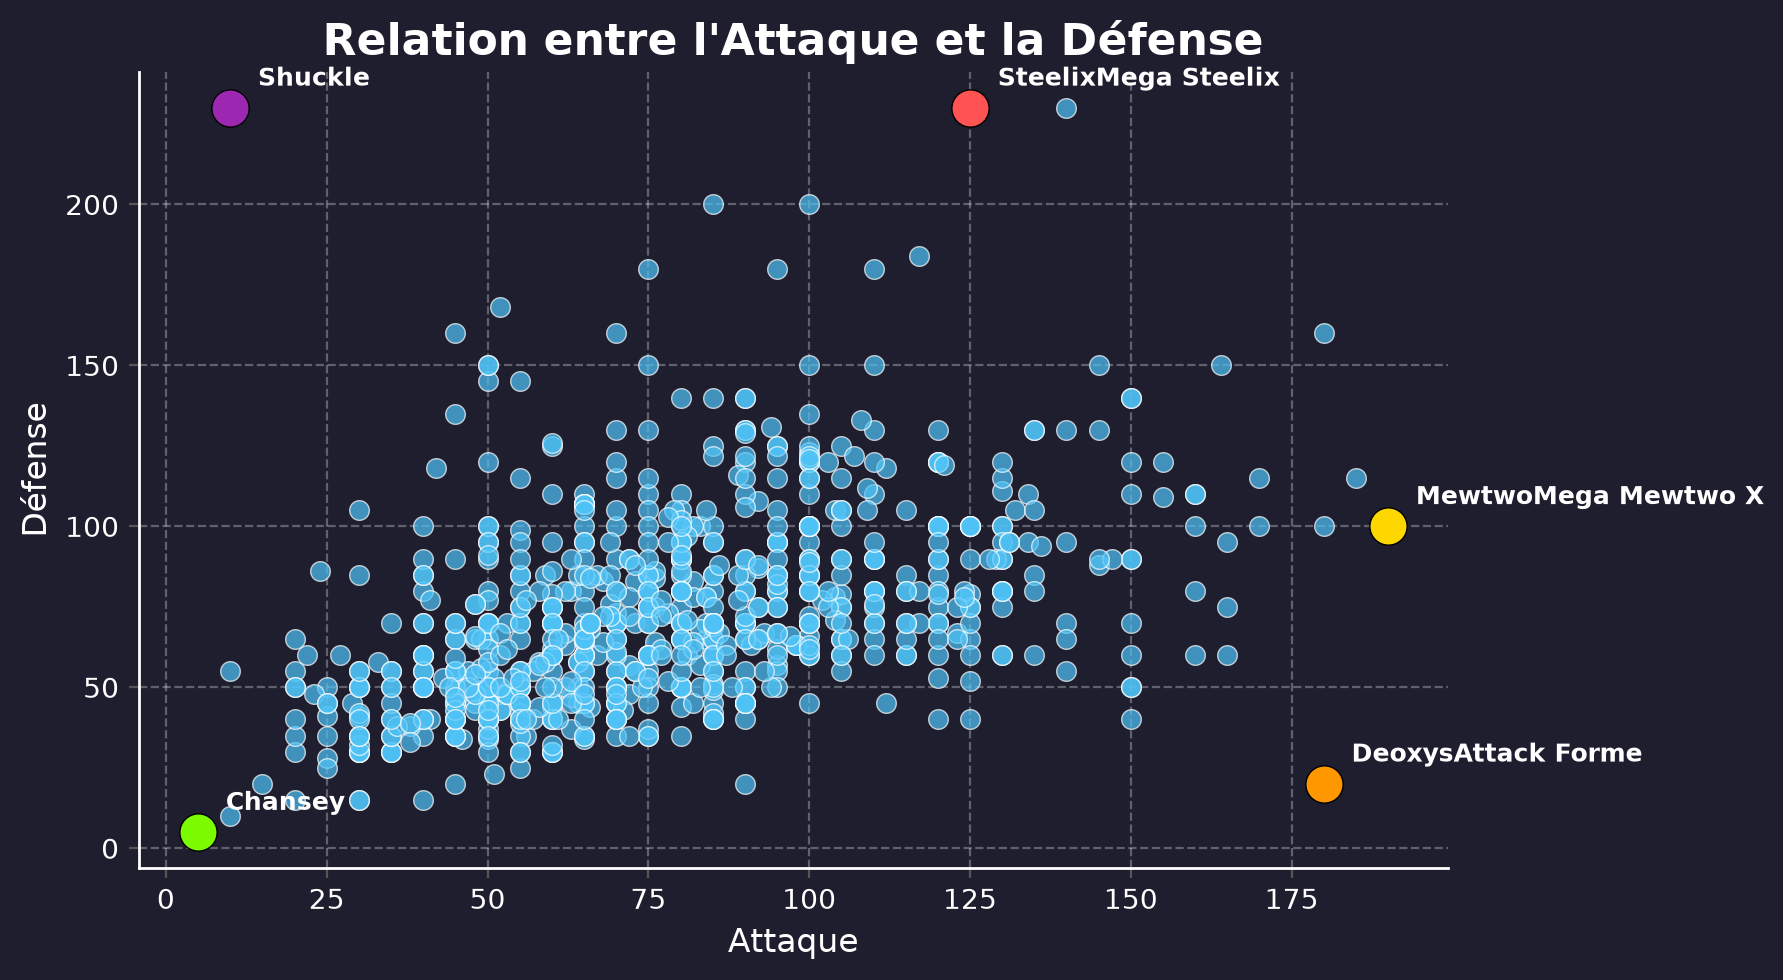

In [47]:
# ==========================
# Scatter Attack / Defense
# ==========================

plt.figure(figsize=(9,5), facecolor="#1E1E2F")
ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Nuage de points
plt.scatter(
    df["Attack"],
    df["Defense"],
    s=50,
    color="#4FC3F7",
    edgecolors="white",
    linewidth=0.5,
    alpha=0.7
)

# Pokémon remarquables
max_attack = df.nlargest(1, "Attack")
min_attack = df.nsmallest(1, "Attack")
max_defense = df.nlargest(1, "Defense")

# Haut gauche : Attack faible + Defense élevée
top_left = df.loc[
    ((df["Attack"] - df["Attack"].min())**2 +
     (df["Defense"] - df["Defense"].max())**2).idxmin()
]

# Bas droite : Attack élevée + Defense faible
bottom_right = df.loc[
    ((df["Attack"] - df["Attack"].max())**2 +
     (df["Defense"] - df["Defense"].min())**2).idxmin()
]


# Points mis en évidence

# Attaque max
plt.scatter(
    max_attack["Attack"], max_attack["Defense"],
    color="#FFD700",
    s=180,
    edgecolors="black",
    zorder=5
)

# Défense max
plt.scatter(
    max_defense["Attack"], max_defense["Defense"],
    color="#FF5252",
    s=180,
    edgecolors="black",
    zorder=5
)

# Attaque min
plt.scatter(
    min_attack["Attack"], min_attack["Defense"],
    color="#7CFC00",
    s=180,
    edgecolors="black",
    zorder=5
)

# Point haut gauche
plt.scatter(
    top_left["Attack"],
    top_left["Defense"],
    color="#9C27B0",
    s=180,
    edgecolors="black",
    zorder=6
)

# Point bas droite
plt.scatter(
    bottom_right["Attack"],
    bottom_right["Defense"],
    color="#FF9800",
    s=180,
    edgecolors="black",
    zorder=6
)

# Fonction annotation pour éviter la répétition
def add_label(data):
    plt.annotate(
        data["Name"],
        (data["Attack"], data["Defense"]),
        xytext=(10, 8),
        textcoords="offset points",
        color="white",
        fontsize=9,
        fontweight="bold"
    )


add_label(max_attack.iloc[0])
add_label(max_defense.iloc[0])
add_label(min_attack.iloc[0])
add_label(top_left)
add_label(bottom_right)

# Axes
plt.xlabel(
    "Attaque",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Défense",
    fontsize=12,
    color="white"
)

plt.title(
    "Relation entre l'Attaque et la Défense",
    fontsize=16,
    color="white",
    fontweight="bold"
)

# Grille
plt.grid(
    True,
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Couleurs axes
plt.xticks(color="white")
plt.yticks(color="white")

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

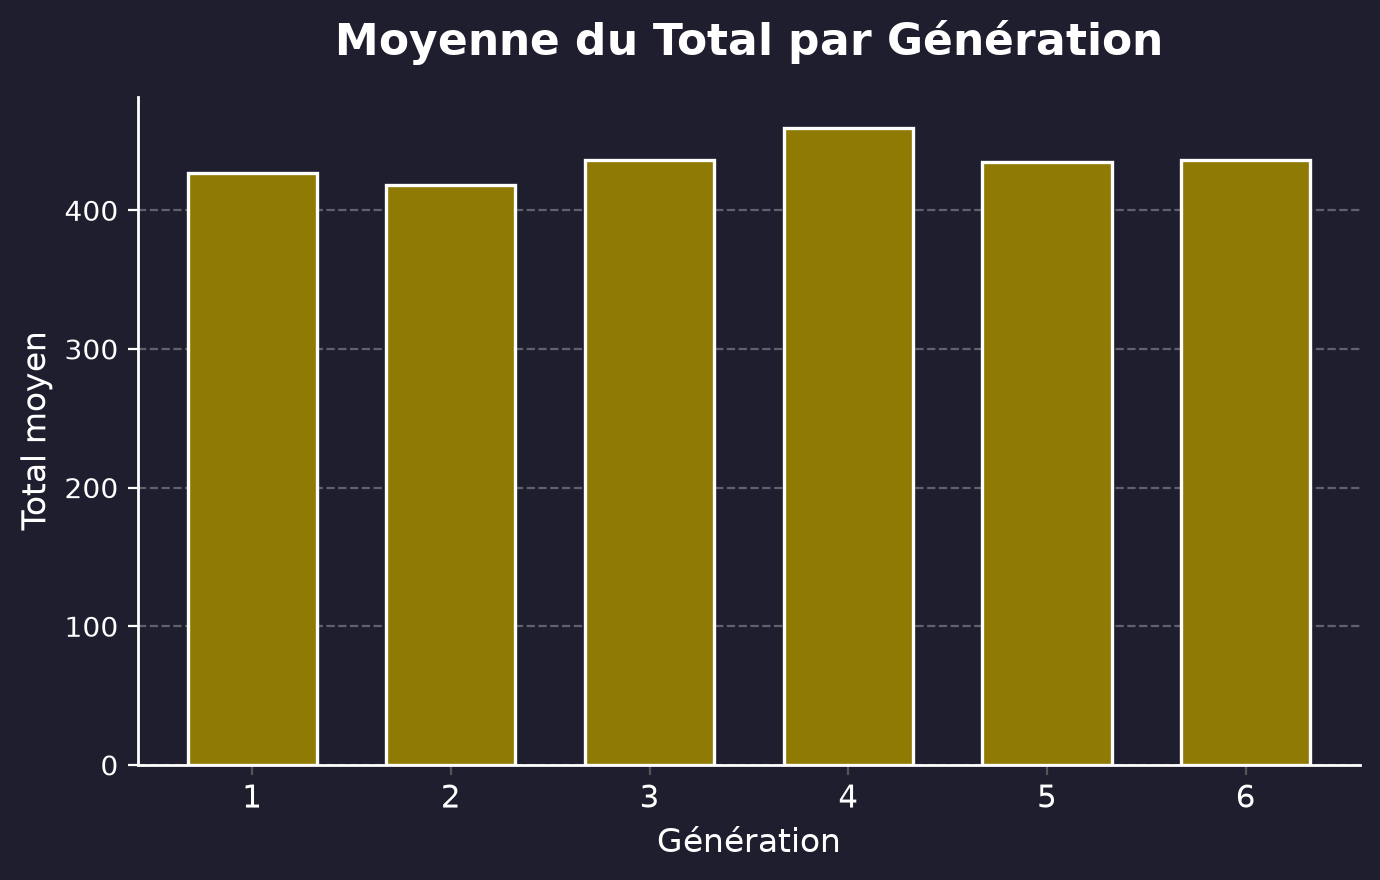

In [48]:
# ==========================
# Total moyen par génération
# ==========================

stats = df.groupby("Generation")[["Total"]].mean()

ax = stats.plot(
    kind="bar",
    figsize=(7,4.5),
    width=0.65,
    color="#8F7A03",       
    edgecolor="white",
    linewidth=1.2,
    legend=False
)

# Fond
ax.set_facecolor("#1E1E2F")
ax.figure.set_facecolor("#1E1E2F")

# Titres
ax.set_title(
    "Moyenne du Total par Génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Génération", fontsize=12, color="white")
ax.set_ylabel("Total moyen", fontsize=12, color="white")

# Axes
ax.set_xticks(range(6))
ax.set_xticklabels(["1", "2", "3", "4", "5", "6"], color="white", fontsize=11)

ax.tick_params(axis="y", colors="white")

# Grille
ax.grid(axis="y", linestyle="--", alpha=0.3, color="white")
ax.grid(axis="x", visible=False)

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

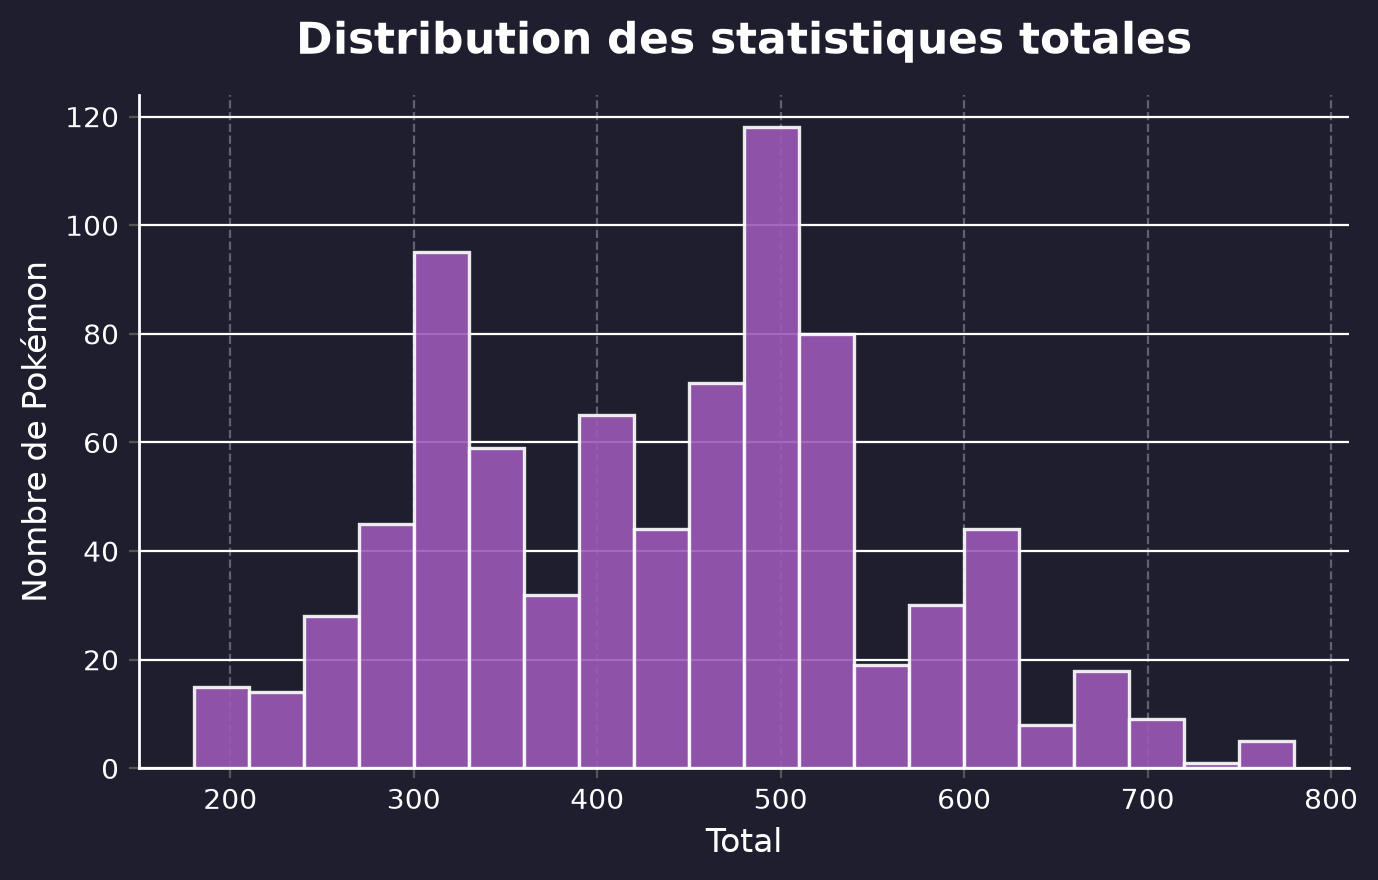

In [49]:
# ==========================
# Distribution du Total
# ==========================

plt.figure(figsize=(7,4.5), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Histogramme
plt.hist(
    df["Total"],
    bins=20,
    color="#9B59B6",          # Violet Pokémon
    edgecolor="white",
    linewidth=1.2,
    alpha=0.9
)

# Titres
plt.title(
    "Distribution des statistiques totales",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

plt.xlabel(
    "Total",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Nombre de Pokémon",
    fontsize=12,
    color="white"
)

# Axes
plt.xticks(color="white")
plt.yticks(color="white")

# Grille
plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Suppression des bordures inutiles
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

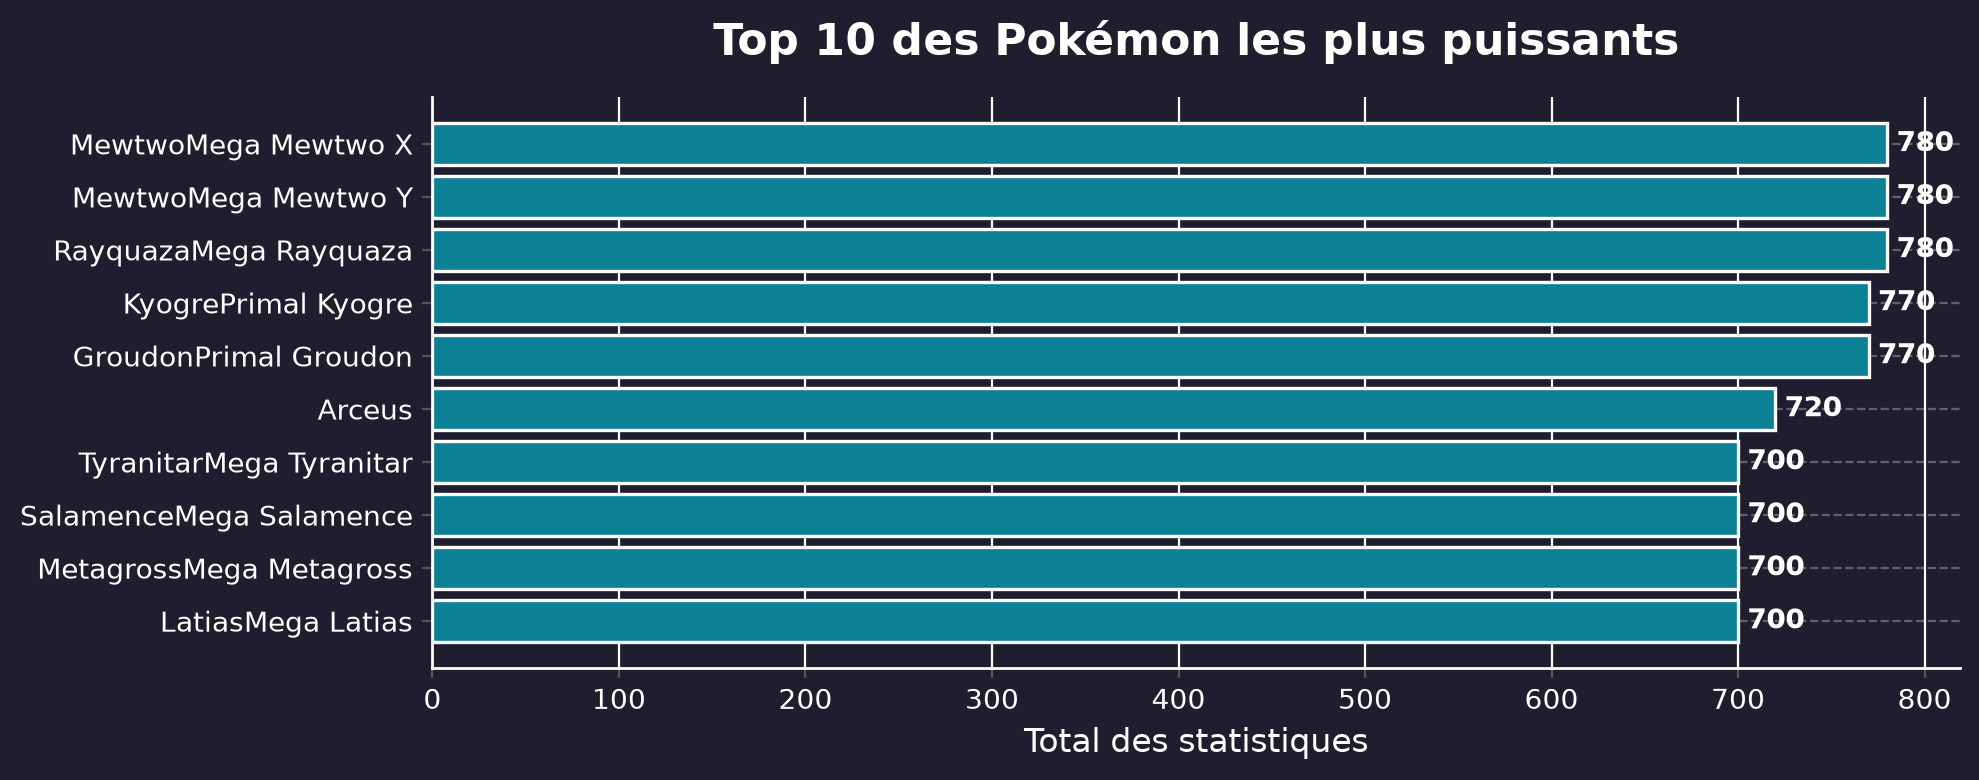

In [50]:
# ==========================
# Top 10 Pokémon
# ==========================

top10 = df.nlargest(10, "Total")

plt.figure(figsize=(10,4), facecolor="#1E1E2F")


ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Barres horizontales
bars = plt.barh(
    top10["Name"],
    top10["Total"],
    color="#0C8196",          # Orange puissant
    edgecolor="white",
    linewidth=1.2
)

# Titre
plt.title(
    "Top 10 des Pokémon les plus puissants",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Total des statistiques",
    fontsize=12,
    color="white"
)

plt.xticks(color="white")
plt.yticks(color="white", fontsize=10)

# Inverser l'ordre pour mettre le meilleur en haut
plt.gca().invert_yaxis()

# Grille
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Ajouter la valeur au bout des barres
for bar in bars:
    plt.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height()/2,
        f"{int(bar.get_width())}",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()




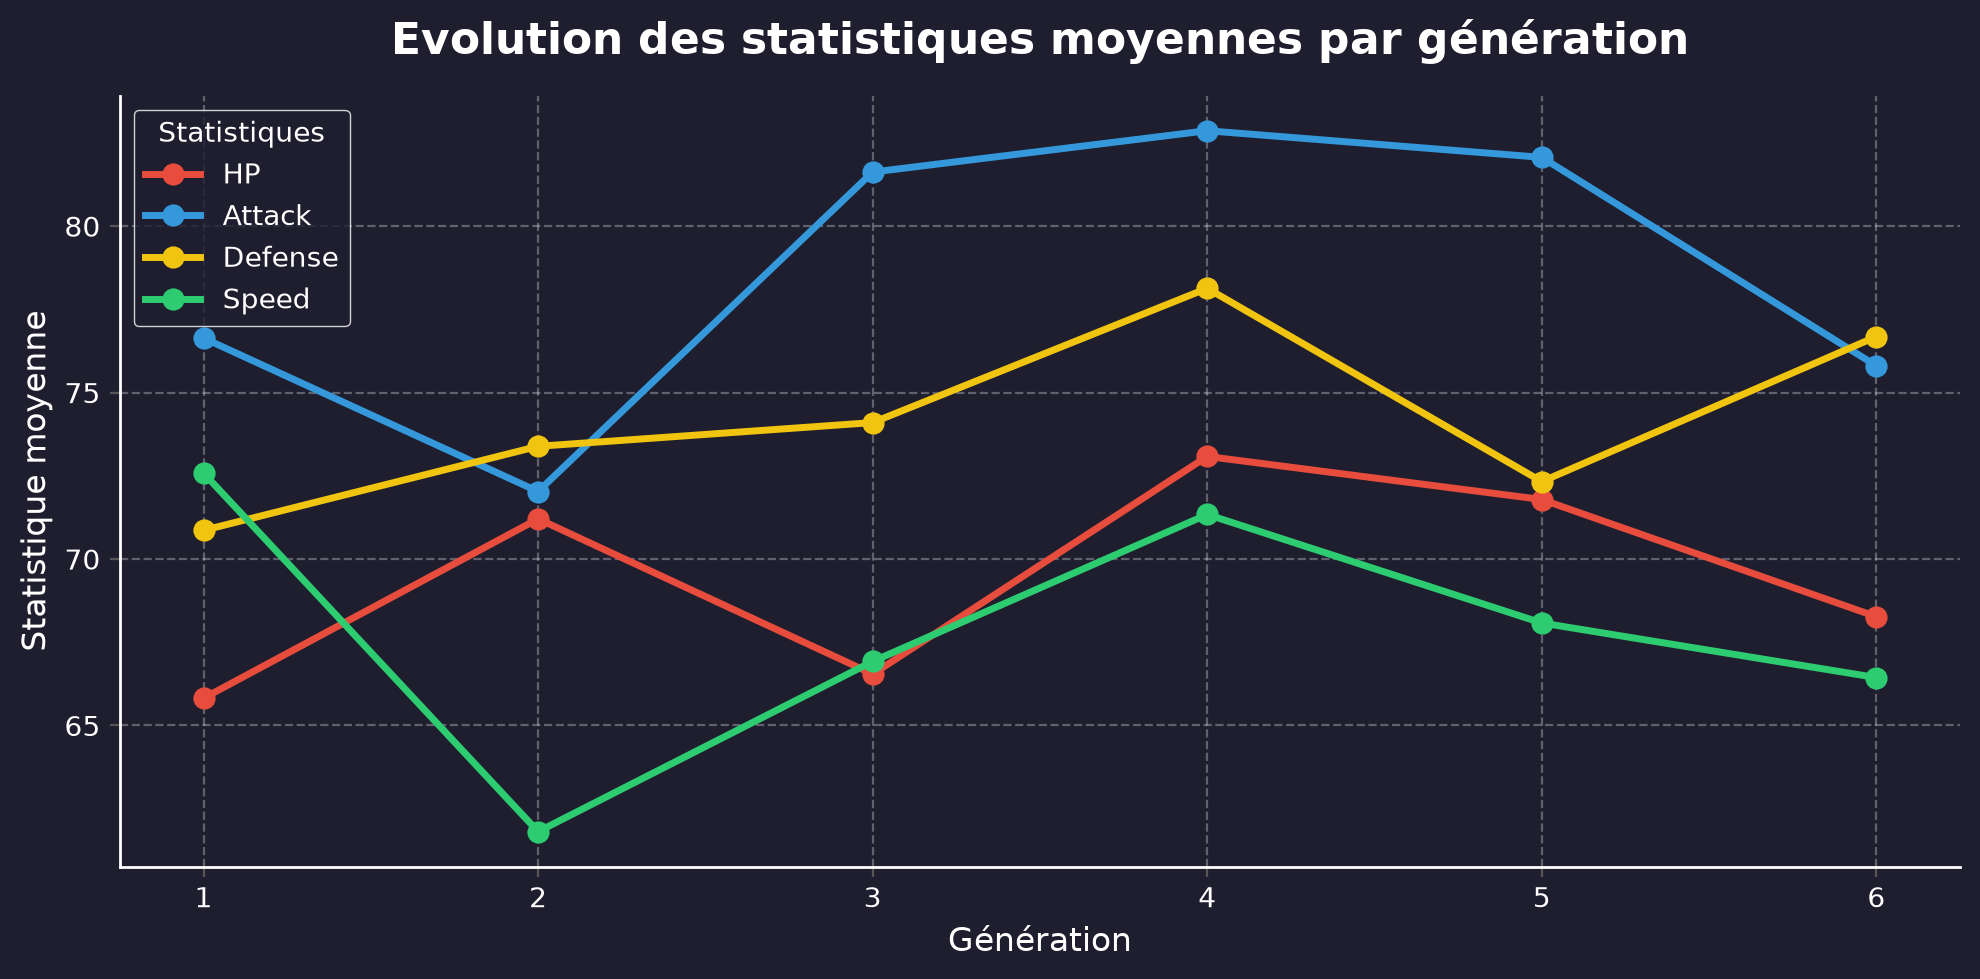

In [51]:
# ==========================
# Evolution par génération
# ==========================

stats_gen = df.groupby("Generation")[
    ["HP", "Attack", "Defense", "Speed"]
].mean()

plt.figure(figsize=(10,5), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Courbes
colors = [
    "#E74C3C",  # HP - Rouge
    "#3498DB",  # Attack - Bleu
    "#F1C40F",  # Defense - Jaune
    "#2ECC71"   # Speed - Vert
]

for stat, color in zip(stats_gen.columns, colors):
    plt.plot(
        stats_gen.index,
        stats_gen[stat],
        marker="o",
        linewidth=2.5,
        markersize=7,
        color=color,
        label=stat
    )

# Titre
plt.title(
    "Evolution des statistiques moyennes par génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Génération",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Statistique moyenne",
    fontsize=12,
    color="white"
)

plt.xticks(
    stats_gen.index,
    color="white"
)

plt.yticks(color="white")

# Grille
plt.grid(
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Légende
legend = plt.legend(
    title="Statistiques",
    facecolor="#1E1E2F",
    edgecolor="white"
)

plt.setp(legend.get_title(), color="white")

for text in legend.get_texts():
    text.set_color("white")

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

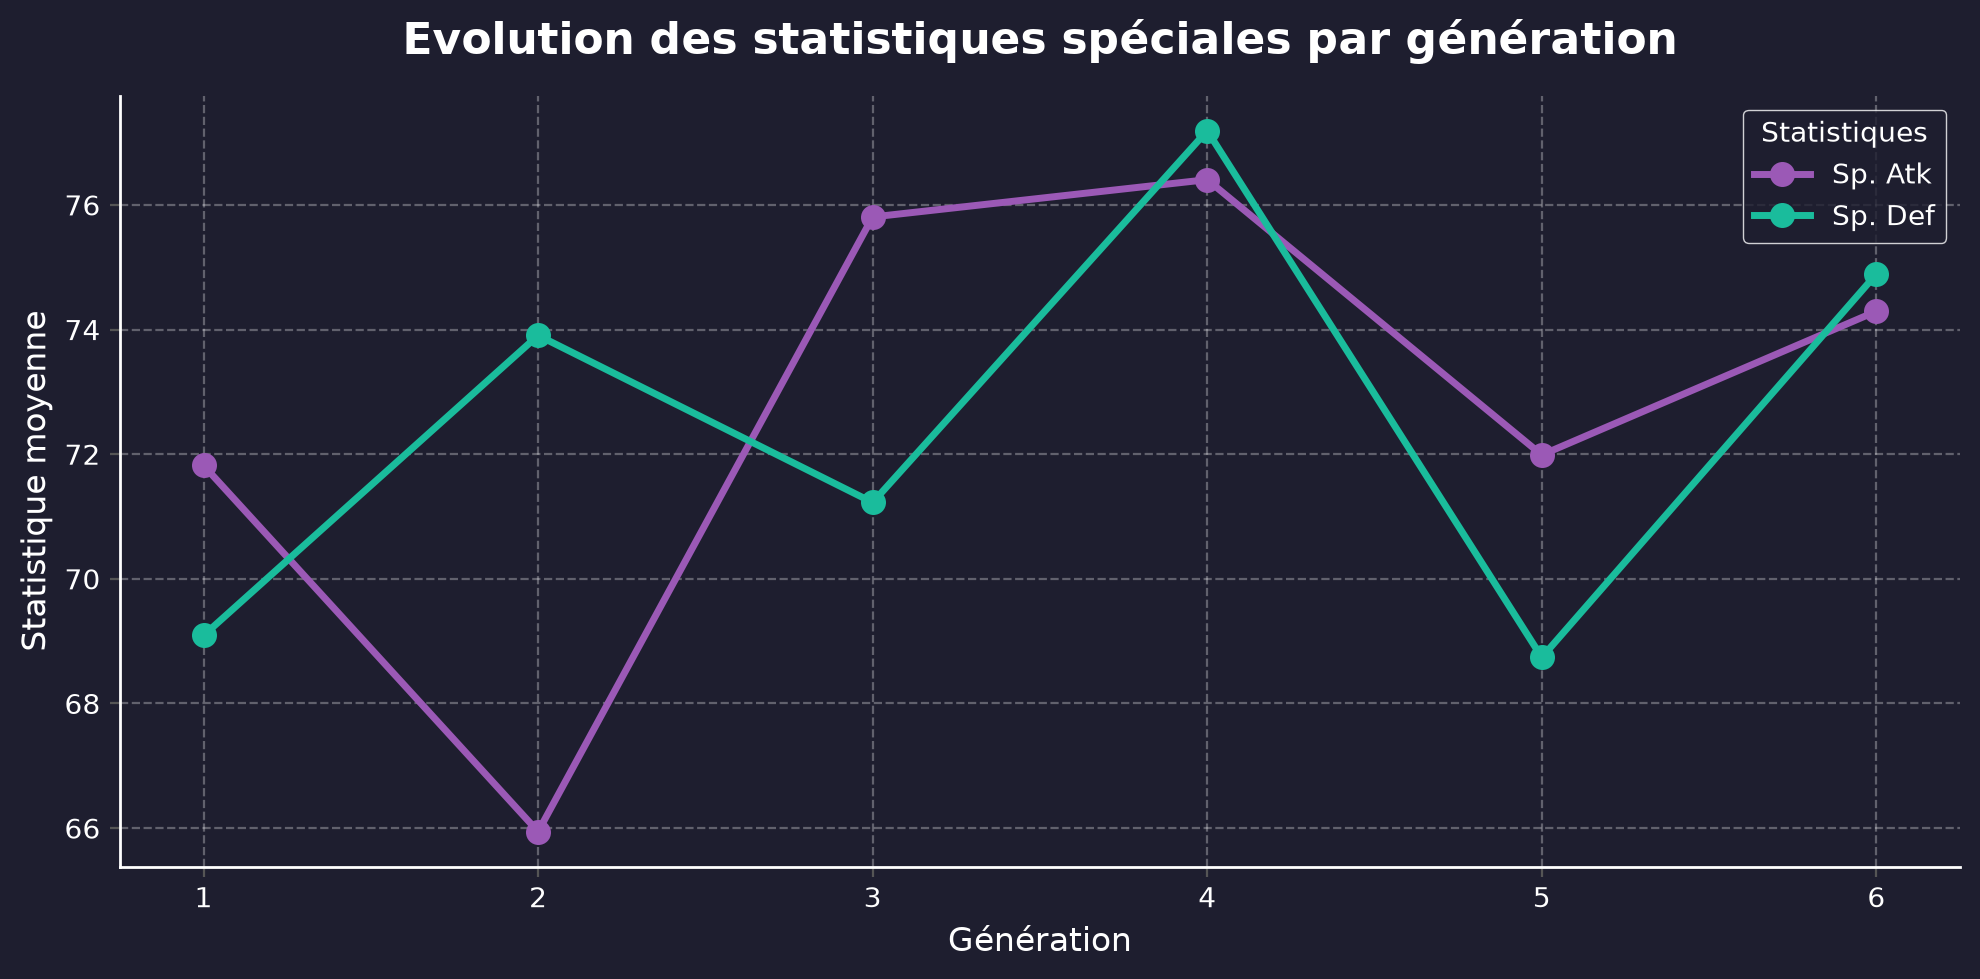

In [52]:
# ==========================
# Evolution Sp par génération
# ==========================

stats_gen = df.groupby("Generation")[
    ["Sp. Atk", "Sp. Def"]
].mean()

plt.figure(figsize=(10,5), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Courbes
colors = {
    "Sp. Atk": "#9B59B6",   # Violet
    "Sp. Def": "#1ABC9C"    # Turquoise
}

for stat in stats_gen.columns:
    plt.plot(
        stats_gen.index,
        stats_gen[stat],
        marker="o",
        markersize=8,
        linewidth=2.5,
        color=colors[stat],
        label=stat
    )

# Titre
plt.title(
    "Evolution des statistiques spéciales par génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Génération",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Statistique moyenne",
    fontsize=12,
    color="white"
)

plt.xticks(
    stats_gen.index,
    color="white"
)

plt.yticks(color="white")

# Grille
plt.grid(
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Légende
legend = plt.legend(
    title="Statistiques",
    facecolor="#1E1E2F",
    edgecolor="white"
)

plt.setp(legend.get_title(), color="white")

for text in legend.get_texts():
    text.set_color("white")


# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()



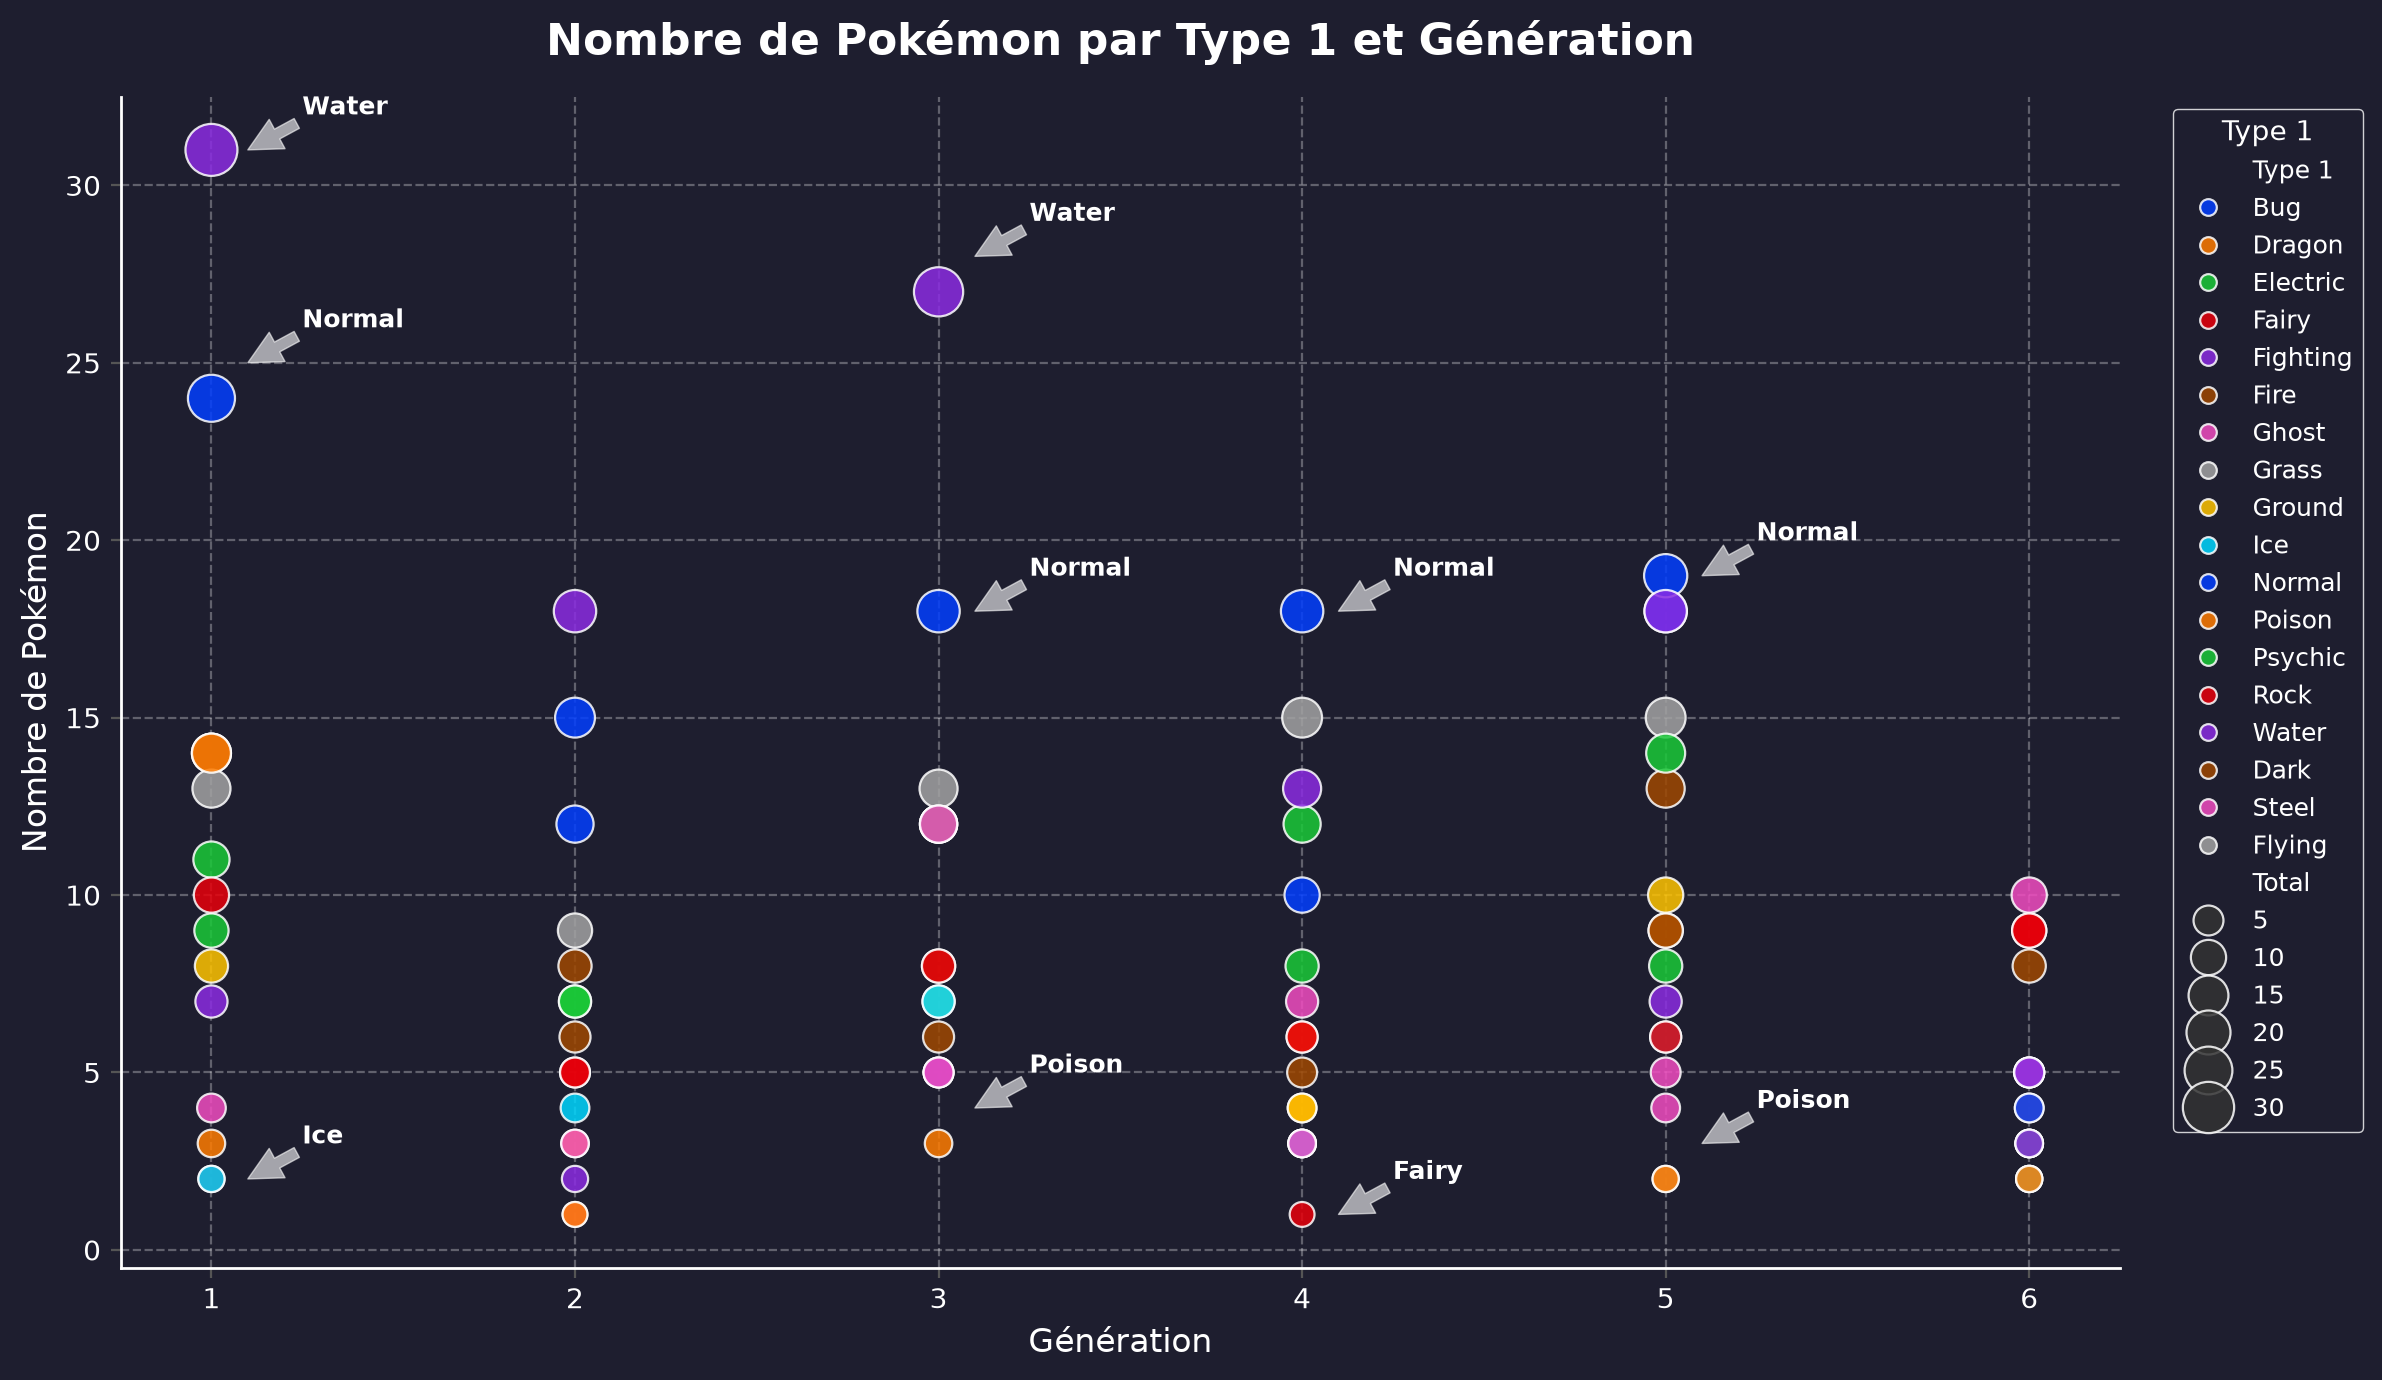

In [53]:
# ==========================
# Type 1 par génération
# ==========================

totals = (
    df.groupby(["Generation", "Type 1"])["Total"]
    .count()
    .reset_index()
)

plt.figure(figsize=(12,7), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Scatter
sns.scatterplot(
    data=totals,
    x="Generation",
    y="Total",
    hue="Type 1",
    size="Total",
    sizes=(80,350),
    palette="bright",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8
)

# Quelques annotations importantes
annotations = [
    ("Water", 1.1, 31),
    ("Water", 3.1, 28),
    ("Normal", 1.1, 25),
    ("Normal", 3.1, 18),
    ("Normal", 4.1, 18),
    ("Normal", 5.1, 19),
    ("Ice", 1.1, 2),
    ("Poison", 3.1, 4),
    ("Fairy", 4.1, 1),
    ("Poison", 5.1, 3)
]

for name, x, y in annotations:
    plt.annotate(
        name,
        xy=(x,y),
        xytext=(x+0.15, y+1),
        color="white",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            color="white",
            alpha=0.6
        )
    )

# Titre
plt.title(
    "Nombre de Pokémon par Type 1 et Génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Génération",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Nombre de Pokémon",
    fontsize=12,
    color="white"
)

plt.xticks(
    color="white"
)

plt.yticks(
    color="white"
)

# Grille
plt.grid(
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Légende
legend = plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    title="Type 1",
    facecolor="#1E1E2F",
    edgecolor="white",
    fontsize=9
)

plt.setp(legend.get_title(), color="white")

for text in legend.get_texts():
    text.set_color("white")

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

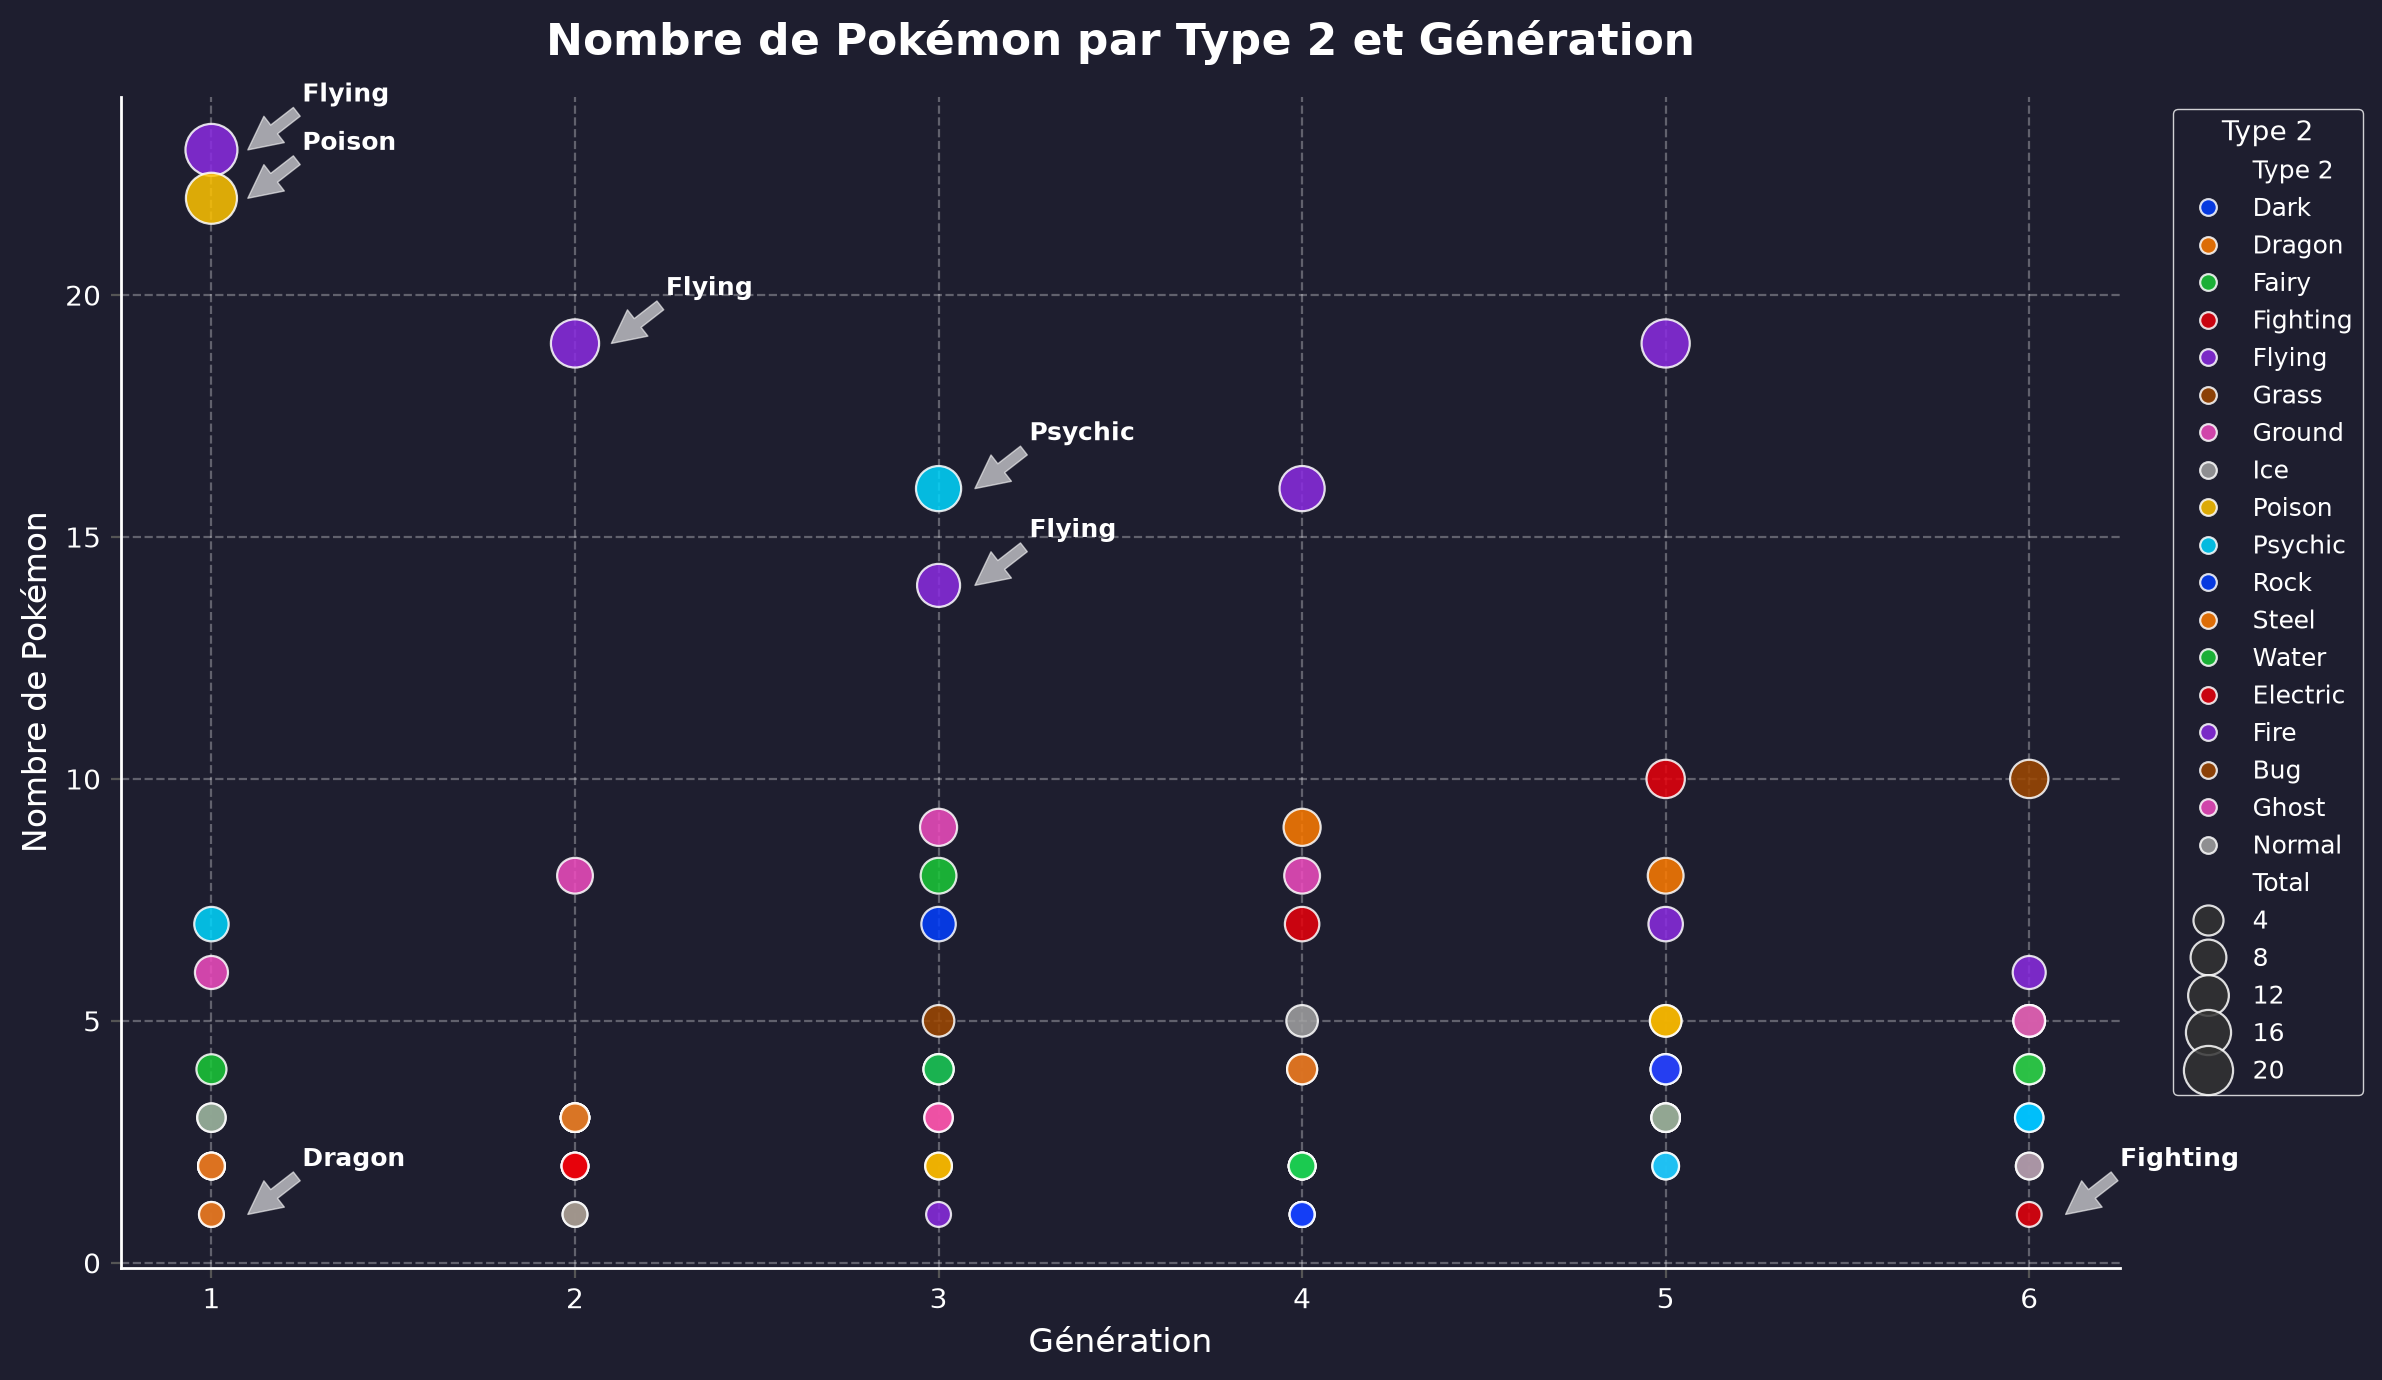

In [54]:
# ==========================
# Type 2 par génération
# ==========================

totals = (
    df.groupby(["Generation", "Type 2"])["Total"]
    .count()
    .reset_index()
)

plt.figure(figsize=(12,7), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Scatter
sns.scatterplot(
    data=totals,
    x="Generation",
    y="Total",
    hue="Type 2",
    size="Total",
    sizes=(80,350),
    palette="bright",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8
)

# Annotations importantes
annotations = [
    ("Flying", 1.1, 23),
    ("Flying", 2.1, 19),
    ("Flying", 3.1, 14),
    ("Water", 3.1, 12000),
    ("Poison", 1.1, 22),
    ("Psychic", 3.1, 16),
    ("Dragon", 1.1, 1),
    ("Fighting", 6.1, 1)
]

for name, x, y in annotations:
    plt.annotate(
        name,
        xy=(x, y),
        xytext=(x+0.15, y+1),
        color="white",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            color="white",
            alpha=0.6
        )
    )

# Titre
plt.title(
    "Nombre de Pokémon par Type 2 et Génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Génération",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Nombre de Pokémon",
    fontsize=12,
    color="white"
)

plt.xticks(color="white")
plt.yticks(color="white")

# Grille
plt.grid(
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Légende
legend = plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    title="Type 2",
    facecolor="#1E1E2F",
    edgecolor="white",
    fontsize=9
)

plt.setp(legend.get_title(), color="white")

for text in legend.get_texts():
    text.set_color("white")

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

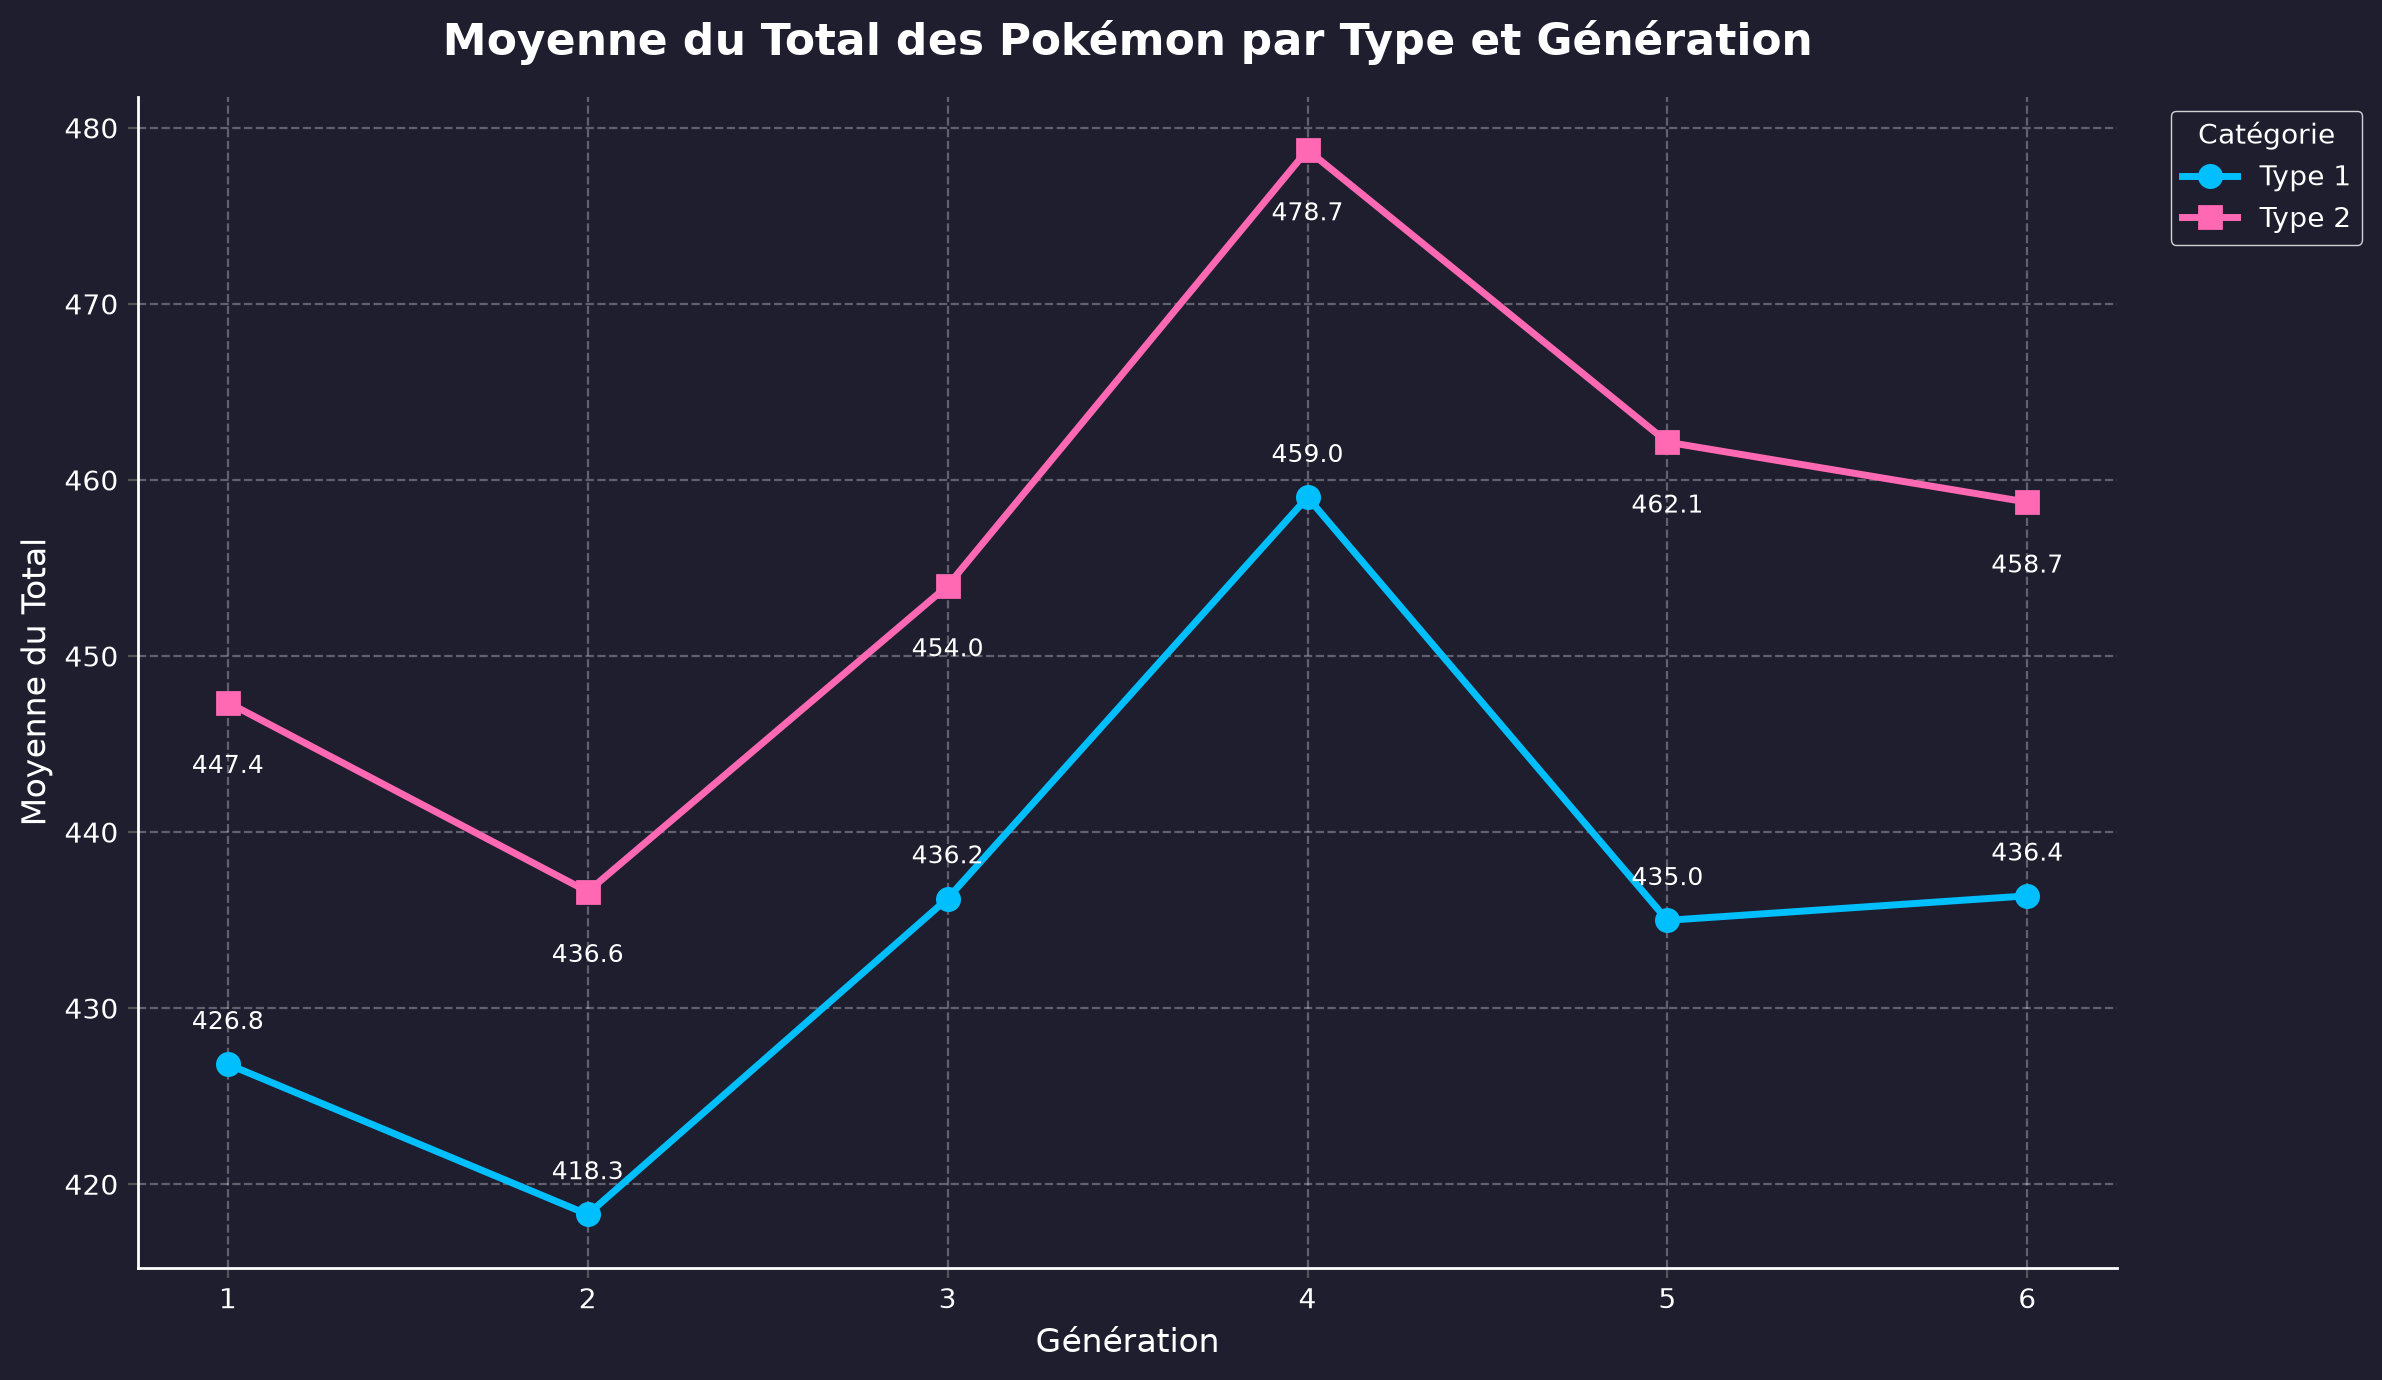

In [55]:
# ==========================
# Moyenne du Total par Type et Génération
# ==========================

type1 = (
    df.groupby("Generation")["Total"]
    .mean()
)

type2 = (
    df.dropna(subset=["Type 2"])
      .groupby("Generation")["Total"]
      .mean()
)

plt.figure(figsize=(12,7), facecolor="#1E1E2F")

ax = plt.gca()
ax.set_facecolor("#1E1E2F")

# Courbes
plt.plot(
    type1.index,
    type1.values,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#00BFFF",
    label="Type 1"
)

plt.plot(
    type2.index,
    type2.values,
    marker="s",
    linewidth=2.5,
    markersize=8,
    color="#FF69B4",
    label="Type 2"
)

# Annotations des valeurs
for x, y in zip(type1.index, type1.values):
    plt.text(
        x,
        y+2,
        f"{y:.1f}",
        color="white",
        fontsize=9,
        ha="center"
    )

for x, y in zip(type2.index, type2.values):
    plt.text(
        x,
        y-4,
        f"{y:.1f}",
        color="white",
        fontsize=9,
        ha="center"
    )

# Titre
plt.title(
    "Moyenne du Total des Pokémon par Type et Génération",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=15
)

# Axes
plt.xlabel(
    "Génération",
    fontsize=12,
    color="white"
)

plt.ylabel(
    "Moyenne du Total",
    fontsize=12,
    color="white"
)

plt.xticks(color="white")
plt.yticks(color="white")

# Grille
plt.grid(
    linestyle="--",
    alpha=0.3,
    color="white"
)

# Légende
legend = plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    title="Catégorie",
    facecolor="#1E1E2F",
    edgecolor="white",
    fontsize=10
)

plt.setp(legend.get_title(), color="white")

for text in legend.get_texts():
    text.set_color("white")

# Bordures
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")

plt.tight_layout()
plt.show()

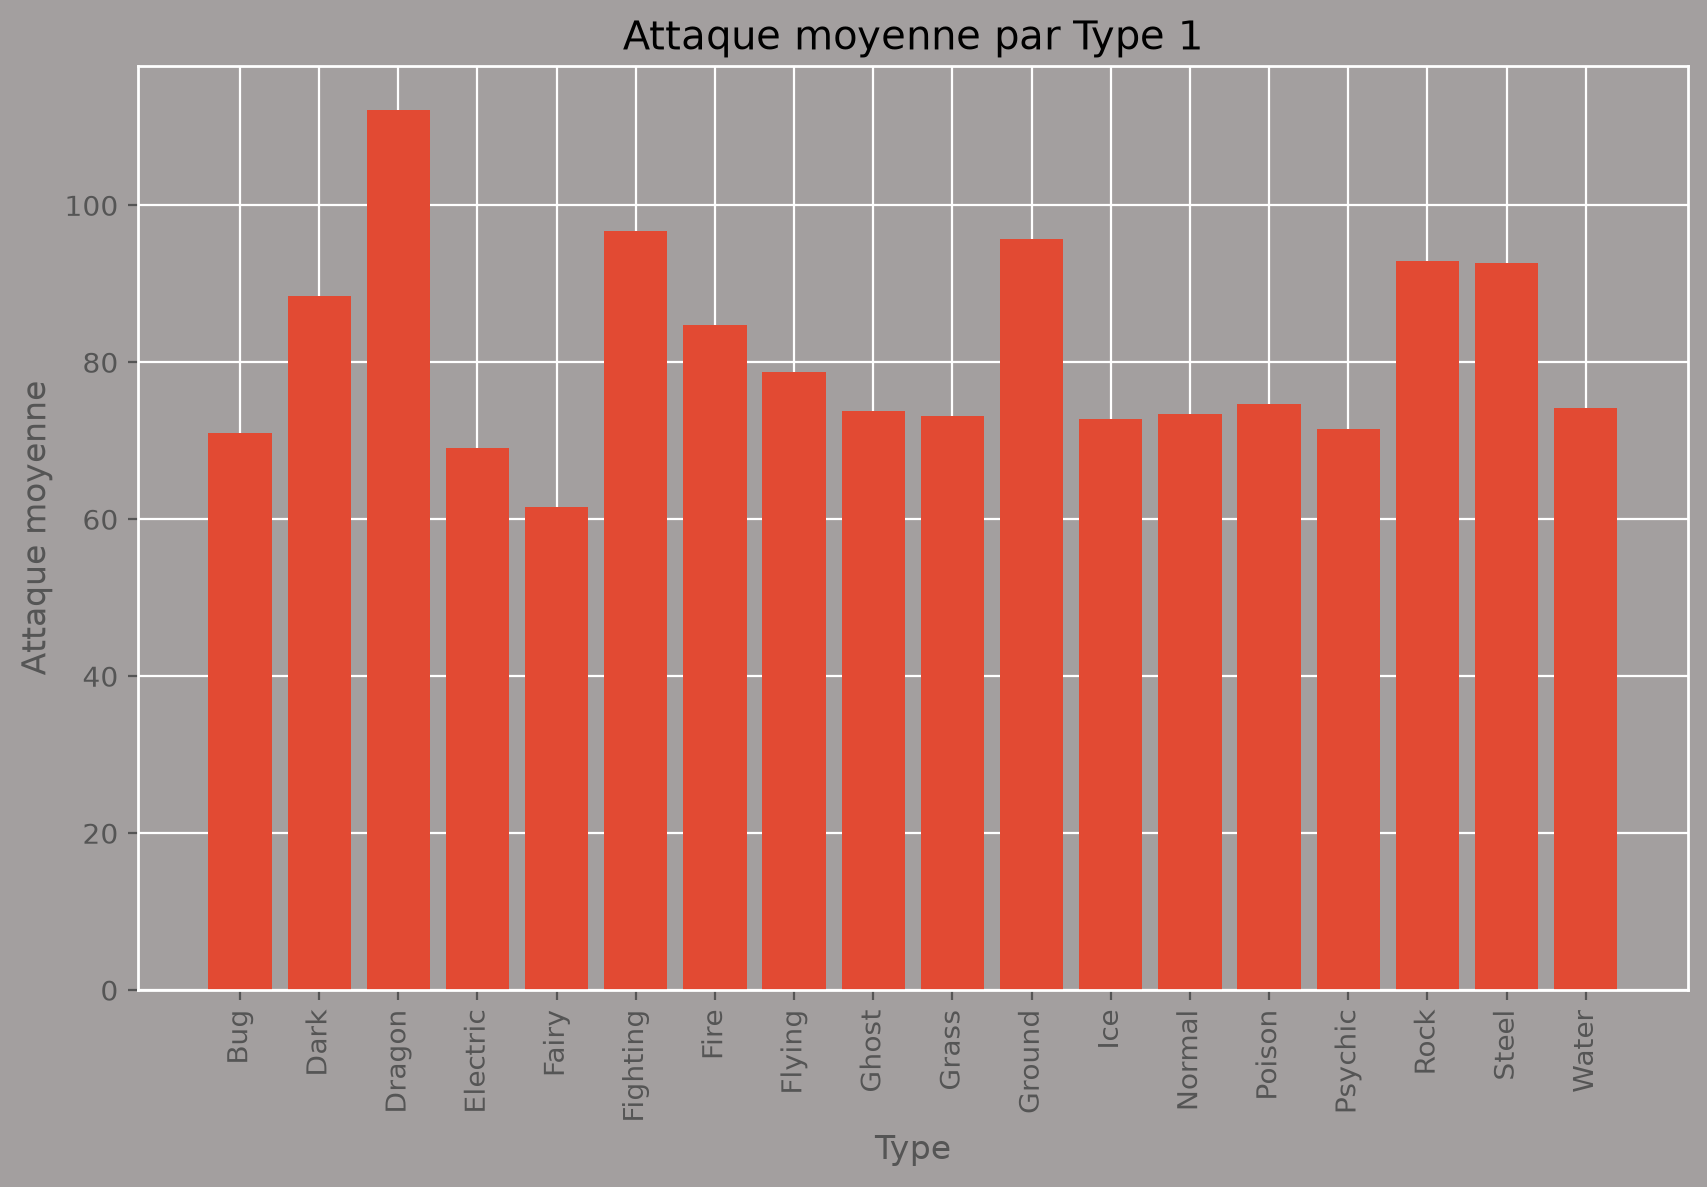

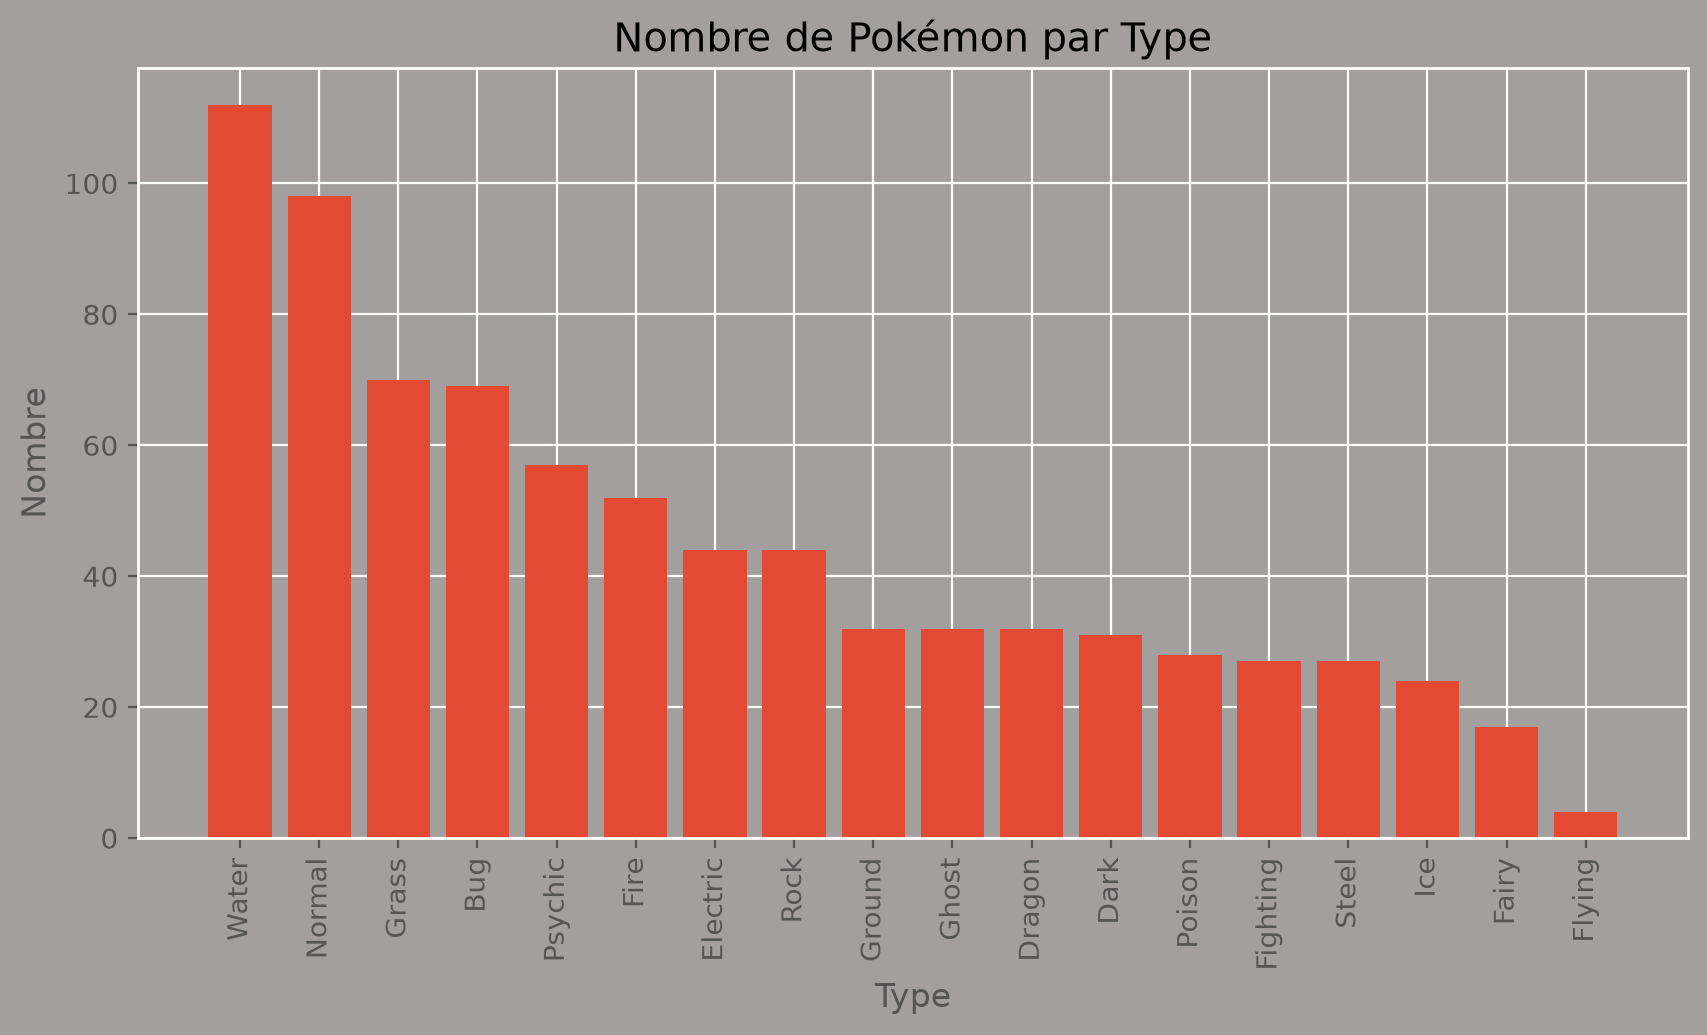

In [56]:

stats = df.groupby("Type 1")["Attack"].mean()

plt.figure(figsize=(10,6))

plt.bar(
    stats.index,
    stats.values
)

plt.xticks(rotation=90)

plt.title("Attaque moyenne par Type 1")
plt.xlabel("Type")
plt.ylabel("Attaque moyenne")

plt.show()

types = df["Type 1"].value_counts()

plt.figure(figsize=(10,5))

plt.bar(
    types.index,
    types.values
)

plt.xticks(rotation=90)

plt.title("Nombre de Pokémon par Type")
plt.xlabel("Type")
plt.ylabel("Nombre")

plt.show()